# Team 8: Gacha | Milestone 2 Data Preparation

**Project:** U.S. domestic aviation activity, airport connectivity, and operational performance (2015–2025).

This notebook documents the source-data checks, transformations, exploratory findings, and processed tables supporting our seven domain questions. The accompanying **Milestone 2 report** contains representative tables and the team's original visualization sketches. Code and data-access instructions are shared through the project GitHub repository.

**Data:** Bureau of Transportation Statistics (BTS) T-100 Domestic Segment, BTS On-Time Performance, and U.S. Census state population estimates. The analysis uses complete calendar years **2015–2025**; partial 2026 T-100 data are loaded for reference but excluded from annual comparisons.

**Interpretation:** T-100 `passengers` represents **departing passenger segments at the origin airport**, not unique travelers or state residents. A connecting traveler may contribute multiple segments. On-Time Performance is a separate reporting-carrier dataset, so its flight counts need not match T-100.

**Input folders (relative to notebook):** `Domestic Segment data/`, `Census Data/`, and `data/On-Time Performance/` (alternatively `On-Time Performance/`). The notebook creates `output/processed/` and `output/samples/`. Adjust paths in the first code cell if necessary.

In [33]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from IPython.display import display

# Notebook beside data folder. Edit only if your actual folder differs.
DATA_DIR = Path('data')
# Use the unzipped folder as supplied, or data/original if that is your project layout.
SOURCE_OPTIONS = [Path('Domestic Segment data'), DATA_DIR / 'original']
RAW_T100_DIR = next((folder for folder in SOURCE_OPTIONS if folder.is_dir() and list(folder.glob('*.csv'))), SOURCE_OPTIONS[0])
CENSUS_DIR_OPTIONS = [DATA_DIR / 'Census Data', Path('Census Data')]
CENSUS_DIR = next((folder for folder in CENSUS_DIR_OPTIONS if folder.is_dir()), CENSUS_DIR_OPTIONS[0])
OUT = Path('output')
PROCESSED, SAMPLES = OUT / 'processed', OUT / 'samples'
for folder in (PROCESSED, SAMPLES):
    folder.mkdir(parents=True, exist_ok=True)
ANALYSIS_START_YEAR, ANALYSIS_END_YEAR = 2015, 2025
MEASURES = ['passengers','departures_performed','seats','freight_lb','mail_lb']

# Define source fields before the raw-schema EDA cell.
COLUMN_ALIASES = {
    'YEAR':'year', 'MONTH':'month',
    'ORIGIN_AIRPORT_ID':'airport_id', 'ORIGIN':'airport',
    'ORIGIN_CITY_NAME':'city', 'ORIGIN_STATE_ABR':'state',
    'DEST_AIRPORT_ID':'dest_airport_id', 'DEST':'destination',
    'AIRLINE_ID':'carrier_id', 'UNIQUE_CARRIER':'carrier_code',
    'CLASS':'service_class', 'PASSENGERS':'passengers',
    'SEATS':'seats', 'DEPARTURES_PERFORMED':'departures_performed',
    'FREIGHT':'freight_lb', 'MAIL':'mail_lb',
}

def export(name, data, preview_sort=None):
    if data is None or data.empty:
        print(f'{name}: no rows, no output generated')
        return None
    if preview_sort: data = data.sort_values(preview_sort)
    data.to_csv(PROCESSED / f'{name}.csv', index=False)
    data.head(100).to_csv(SAMPLES / f'{name}_sample.csv', index=False)
    print(f'{name}: {len(data):,} rows, sample {min(len(data),100)} rows')
    display(data.head(5))
    return data

# Run-time path check makes the data layout explicit, without guessing filenames.
if not RAW_T100_DIR.is_dir():
    raise FileNotFoundError(f'Original yearly CSV directory missing: {RAW_T100_DIR.resolve()}. '
        'Place the unzipped yearly CSV directory beside the notebook or configure RAW_T100_DIR.')


## 1. Source data and preprocessing

The detailed T-100 data retain origin/destination airport IDs, carrier IDs, service class, year/month, passengers, seats, departures, freight, and mail. The pipeline produces three main views:

- `raw`: source records from 2015–2026, including partial 2026.
- `analysis`: records from 2015–2025 for comparable annual results.
- `f`: scheduled passenger service (BTS Class `F`) within `analysis`.

The service-class distinction is essential: **Q1** compares all classes and Class F; **Q2–Q5** and the T-100 indicators in **Q7** focus on Class F. Annual totals are attributed to the **origin** airport.

### 1.1 Inspect and load original T-100 files

Each original CSV is identified using its `YEAR` field, not its filename. A schema/sample check runs **before** the loader selects the 16 fields needed for the project. The loader then reads the source data in chunks, standardizes column names and numeric types, and combines the files without altering them.

### 1.2 Original-file schema review

**Purpose:** Check whether all yearly files expose the same fields and identify what is lost when selecting the project's columns.

**Method:** Inspect every source CSV's column names and up to 2,000 sample rows per file. Missingness and duplicate counts from this cell are **sample diagnostics**, not whole-file estimates.

**Finding from the saved run:** Each of 12 T-100 files had **45 source columns**; the analysis loader retained **16**. Excluded columns include aircraft type, distance, scheduled departures, and payload. Findings about those excluded fields are outside the scope of the current processed dataset.

In [34]:
# Inspect original file schemas BEFORE usecols filters them out.
# Uses a per-file sample to limit memory; data-quality rates here are sample estimates.
source_profiles = []
schema_sets = {}
for source_file in sorted(RAW_T100_DIR.glob('*.csv')):
    probe = pd.read_csv(source_file, nrows=2000, low_memory=False)
    cols = [str(c).strip().upper() for c in probe.columns]
    schema_sets[source_file.name] = set(cols)
    source_profiles.append({
        'source_file': source_file.name,
        'columns_in_original': len(probe.columns),
        'sample_rows': len(probe),
        'sample_missing_cells_pct': round(100 * probe.isna().to_numpy().mean(), 2),
        'sample_duplicate_rows': int(probe.duplicated().sum()),
        'retained_columns': sum(c in COLUMN_ALIASES for c in cols),
    })
source_overview = pd.DataFrame(source_profiles)
display(source_overview)
if schema_sets:
    shared_source_columns = set.intersection(*schema_sets.values())
    all_source_columns = set.union(*schema_sets.values())
    selected_source_columns = set(COLUMN_ALIASES) & all_source_columns
    dropped_source_columns = sorted(all_source_columns - set(COLUMN_ALIASES))
    print('Original columns (union):', len(all_source_columns))
    print('Present in every source file:', len(shared_source_columns))
    print('Retained by loader:', len(selected_source_columns))
    print('Not retained by loader (first 30):', dropped_source_columns[:30])
    display(pd.DataFrame({'retained_source_column': sorted(selected_source_columns)}))

,source_file,columns_in_original,sample_rows,sample_missing_cells_pct,sample_duplicate_rows,retained_columns
0,T_T100D_SEGMENT_US_CARRIER_ONLY 10.csv,45,2000,0.0,0,16
1,T_T100D_SEGMENT_US_CARRIER_ONLY 11.csv,45,2000,0.0,0,16
2,T_T100D_SEGMENT_US_CARRIER_ONLY 13.csv,45,2000,0.0,0,16
3,T_T100D_SEGMENT_US_CARRIER_ONLY 14.csv,45,2000,0.0,0,16
4,T_T100D_SEGMENT_US_CARRIER_ONLY 2.csv,45,2000,0.0,0,16
5,T_T100D_SEGMENT_US_CARRIER_ONLY 3.csv,45,2000,0.0,0,16
6,T_T100D_SEGMENT_US_CARRIER_ONLY 4.csv,45,2000,0.0,0,16
7,T_T100D_SEGMENT_US_CARRIER_ONLY 5.csv,45,2000,0.0,0,16
8,T_T100D_SEGMENT_US_CARRIER_ONLY 6.csv,45,2000,0.0,0,16
9,T_T100D_SEGMENT_US_CARRIER_ONLY 7.csv,45,2000,0.0,0,16


Original columns (union): 45
Present in every source file: 45
Retained by loader: 16
Not retained by loader (first 30): ['AIRCRAFT_CONFIG', 'AIRCRAFT_GROUP', 'AIRCRAFT_TYPE', 'AIR_TIME', 'CARRIER', 'CARRIER_GROUP', 'CARRIER_GROUP_NEW', 'CARRIER_NAME', 'DEPARTURES_SCHEDULED', 'DEST_AIRPORT_SEQ_ID', 'DEST_CITY_MARKET_ID', 'DEST_CITY_NAME', 'DEST_STATE_ABR', 'DEST_STATE_FIPS', 'DEST_STATE_NM', 'DEST_WAC', 'DISTANCE', 'DISTANCE_GROUP', 'ORIGIN_AIRPORT_SEQ_ID', 'ORIGIN_CITY_MARKET_ID', 'ORIGIN_STATE_FIPS', 'ORIGIN_STATE_NM', 'ORIGIN_WAC', 'PAYLOAD', 'QUARTER', 'RAMP_TO_RAMP', 'REGION', 'UNIQUE_CARRIER_ENTITY', 'UNIQUE_CARRIER_NAME']


,retained_source_column
0,AIRLINE_ID
1,CLASS
2,DEPARTURES_PERFORMED
3,DEST
4,DEST_AIRPORT_ID
5,FREIGHT
6,MAIL
7,MONTH
8,ORIGIN
9,ORIGIN_AIRPORT_ID


In [35]:
REQUIRED = {'YEAR','MONTH','ORIGIN_AIRPORT_ID','DEST_AIRPORT_ID','AIRLINE_ID',
            'CLASS','PASSENGERS','SEATS','DEPARTURES_PERFORMED','FREIGHT','MAIL'}
NUMERIC = ['year','month','airport_id','dest_airport_id','carrier_id'] + MEASURES

def load_yearly_csvs(folder, chunksize=150_000):
    paths = sorted(folder.glob('*.csv'))
    if not paths:
        raise FileNotFoundError(f'No CSV files in {folder.resolve()}')
    parts = []
    counts = []
    for path in paths:
        rows = 0
        for chunk in pd.read_csv(path, chunksize=chunksize, low_memory=False,
                                 usecols=lambda col: col.upper().strip() in COLUMN_ALIASES):
            chunk.columns = chunk.columns.str.upper().str.strip()
            missing = REQUIRED.difference(chunk.columns)
            if missing:
                raise ValueError(f'{path.name} missing BTS columns: {sorted(missing)}')
            chunk = chunk.rename(columns=COLUMN_ALIASES)
            for col in NUMERIC:
                chunk[col] = pd.to_numeric(chunk[col], errors='coerce')
            if chunk['year'].isna().any():
                raise ValueError(f'{path.name} contains missing or invalid YEAR values')
            chunk = chunk[chunk.year.between(2015, 2026)].copy()
            chunk['service_class'] = chunk['service_class'].astype('string').str.strip().str.upper()
            for col in ['airport','destination','city','state','carrier_code']:
                if col not in chunk.columns: chunk[col] = pd.NA
            for col in MEASURES:
                chunk[col] = chunk[col].fillna(0)
            rows += len(chunk)
            parts.append(chunk)
        counts.append((path.name, rows))
    if not parts:
        raise ValueError('The CSV files have no valid 2015–2026 records')
    combined = pd.concat(parts, ignore_index=True)
    combined['year'] = combined['year'].astype('int64')
    print(f'Loaded {len(paths)} yearly source files, {len(combined):,} rows, years {combined.year.min()}–{combined.year.max()}')
    display(pd.DataFrame(counts, columns=['file','rows_loaded']))
    display(combined.groupby('year').agg(rows=('month','size'), months=('month','nunique'), last_month=('month','max')).reset_index())
    return combined

raw = load_yearly_csvs(RAW_T100_DIR)
analysis = raw[raw.year.between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)].copy()
print(f'Analysis: {len(analysis):,} rows in {ANALYSIS_START_YEAR}–{ANALYSIS_END_YEAR}; 2026 remains in raw.')
# All services for Q1; F only for Q2–Q5 and scheduled passenger Q7.
master = analysis[analysis.service_class.isin(['F','G','L','P'])].copy()
f = master[master.service_class.eq('F')].copy()
# Each raw record is a segment from the origin, not an airport arrival total.
master = master.rename(columns={'airport_id':'airport_id'})


Loaded 12 yearly source files, 4,556,365 rows, years 2015–2026


,file,rows_loaded
0,T_T100D_SEGMENT_US_CARRIER_ONLY 10.csv,370518
1,T_T100D_SEGMENT_US_CARRIER_ONLY 11.csv,379279
2,T_T100D_SEGMENT_US_CARRIER_ONLY 13.csv,367360
3,T_T100D_SEGMENT_US_CARRIER_ONLY 14.csv,392496
4,T_T100D_SEGMENT_US_CARRIER_ONLY 2.csv,266332
5,T_T100D_SEGMENT_US_CARRIER_ONLY 3.csv,455857
6,T_T100D_SEGMENT_US_CARRIER_ONLY 4.csv,437871
7,T_T100D_SEGMENT_US_CARRIER_ONLY 5.csv,424178
8,T_T100D_SEGMENT_US_CARRIER_ONLY 6.csv,408432
9,T_T100D_SEGMENT_US_CARRIER_ONLY 7.csv,381352


,year,rows,months,last_month
0,2015,367360,12,12
1,2016,379279,12,12
2,2017,370518,12,12
3,2018,377202,12,12
4,2019,392496,12,12
5,2020,295488,12,12
6,2021,381352,12,12
7,2022,408432,12,12
8,2023,424178,12,12
9,2024,437871,12,12


Analysis: 4,290,033 rows in 2015–2025; 2026 remains in raw.


### 1.3 Data coverage and service classes

**Purpose:** Establish coverage before restricting the analysis to scheduled passenger services.

**Method:** Count records, airports, carriers, route pairs, and reporting months, then summarize passenger and freight activity by service class.

**Saved results:** The loader read **4,556,365** records (2015–2026), of which **4,290,033** belong to 2015–2025. All twelve months appear in each year from 2015 to 2025; the available 2026 file contains seven months. Class F contributes approximately **75.6% of analyzed records** and **99.67% of passenger segments**.

**Decision:** Retain all classes for broad Q1 comparisons, but use Class F for passenger recovery, connectivity, and capacity analyses. The presence of all twelve T-100 months does not independently prove every flight was reported.

In [36]:
# Full-row coverage for retained fields, BEFORE excluding service classes.
print(f'Loaded raw segment rows (2015–2026): {len(raw):,}')
print(f'Complete analysis-period rows (2015–2025): {len(analysis):,}')
print('Analysis years:', sorted(analysis.year.dropna().unique().astype(int).tolist()))
print('Origin airports:', analysis.airport_id.nunique())
print('Airline IDs:', analysis.carrier_id.nunique())
print('Origin-to-destination pairs:', analysis[['airport_id','dest_airport_id']].drop_duplicates().shape[0])
annual_coverage = (raw.groupby('year', as_index=False)
    .agg(rows=('month','size'), months_present=('month','nunique'),
         origin_airports=('airport_id','nunique'), carriers=('carrier_id','nunique')))
display(annual_coverage)
print('Caution: 2026 is excluded from annual conclusions because the year is incomplete.')

service_profile = (analysis.groupby('service_class', dropna=False)
    .agg(segment_rows=('year','size'), passengers=('passengers','sum'),
         seats=('seats','sum'), departures=('departures_performed','sum'),
         freight_lb=('freight_lb','sum'))
    .reset_index().sort_values('segment_rows', ascending=False))
service_profile['row_share_pct'] = 100 * service_profile.segment_rows / len(analysis)
service_profile['passenger_share_pct'] = (100 * service_profile.passengers /
                                           service_profile.passengers.sum())
display(service_profile.round(2))

Loaded raw segment rows (2015–2026): 4,556,365
Complete analysis-period rows (2015–2025): 4,290,033
Analysis years: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Origin airports: 2021
Airline IDs: 158
Origin-to-destination pairs: 86325


,year,rows,months_present,origin_airports,carriers
0,2015,367360,12,1211,126
1,2016,379279,12,1204,128
2,2017,370518,12,1238,124
3,2018,377202,12,1281,125
4,2019,392496,12,1288,119
5,2020,295488,12,1230,113
6,2021,381352,12,1391,113
7,2022,408432,12,1346,110
8,2023,424178,12,1317,107
9,2024,437871,12,1331,108


Caution: 2026 is excluded from annual conclusions because the year is incomplete.


,service_class,segment_rows,passengers,seats,departures,freight_lb,row_share_pct,passenger_share_pct
0,F,3243864,8.024121e+09,1.008086e+10,85086873.0,1.367383e+10,75.61,99.67
2,L,524192,2.688328e+07,6.154373e+07,1458662.0,4.969957e+08,12.22,0.33
1,G,402740,5.501000e+03,2.644630e+05,5278212.0,2.128209e+11,9.39,0.00
3,P,119237,4.554000e+03,5.291040e+05,908616.0,5.271251e+10,2.78,0.00


### 1.4 Data-quality checks

**Purpose:** Identify records requiring care before interpreting totals or ratios.

**Method:** Inspect missing values, zero/negative measures, exact duplicates across retained fields, and cases where recorded passengers exceed seats.

**Saved results:** The retained dataset contains **5,552 exact duplicate rows**, **209 records with missing carrier identifiers**, and **184 Class F rows with passengers greater than seats**. These are flags for investigation, not records automatically removed.

**Caveat:** The import step fills missing additive measures with zero. Therefore, a zero in the loaded table does not always distinguish a genuine zero from a missing source value; the original-source check should be consulted before claiming there are no missing numerical observations.

In [37]:
# Coverage and data-quality checks on ALL retained raw rows.
quality = pd.DataFrame({
    'field': raw.columns,
    'missing_count': [int(raw[c].isna().sum()) for c in raw.columns],
    'missing_pct': [100 * raw[c].isna().mean() for c in raw.columns],
    'distinct_nonnull': [raw[c].nunique(dropna=True) for c in raw.columns],
}).sort_values('missing_count', ascending=False)
display(quality.round(2))
print('Exact duplicates across retained fields:', f'{raw.duplicated().sum():,}')
for c in ['passengers','seats','departures_performed']:
    print(f'{c}: zero={raw[c].eq(0).sum():,}; negative={raw[c].lt(0).sum():,}')
print('Class F records in analysis:', f'{len(f):,}')
print('Other classes excluded from scheduled-passenger analysis:', f'{len(analysis) - len(f):,}')
print('Class F passenger share (%):', round(100*f.passengers.sum()/analysis.passengers.sum(),2))
# These tests are diagnostics, not automatic corrections.
invalid_utilization = f[f.seats.gt(0) & f.passengers.gt(f.seats)]
print('Class F segment rows with passengers > seats:', f'{len(invalid_utilization):,}')

,field,missing_count,missing_pct,distinct_nonnull
5,carrier_code,209,0.0,158
6,carrier_id,209,0.0,158
0,departures_performed,0,0.0,871
1,seats,0,0.0,35402
2,passengers,0,0.0,37373
3,freight_lb,0,0.0,330393
4,mail_lb,0,0.0,93039
7,airport_id,0,0.0,2046
8,airport,0,0.0,2052
9,city,0,0.0,1828


Exact duplicates across retained fields: 5,552
passengers: zero=845,243; negative=0
seats: zero=550,033; negative=0
departures_performed: zero=20,246; negative=0
Class F records in analysis: 3,243,864
Other classes excluded from scheduled-passenger analysis: 1,046,169
Class F passenger share (%): 99.67
Class F segment rows with passengers > seats: 184


### 1.5 Annual passenger trends

**Purpose:** Identify major changes in scheduled domestic passenger activity and establish an appropriate baseline for Q2.

**Method:** Sum Class F departing passenger segments by year and calculate a recovery index with **2019 = 100**. Compare Class F with the all-service totals. The plots below are **exploratory analyses**, not the team's required visualization sketches.

,year,passengers_all,rows_all,seats_all,departures_all,passengers_F,rows_F,seats_F,departures_F,class_F_passenger_share_pct,passenger_index_2019_100,passenger_change_yoy_pct
0,2015,707523169.0,367360,8.584239e+08,8665933.0,705333022.0,282335,8.542514e+08,8059689.0,99.69,86.18,NaN
1,2016,730650148.0,379279,8.961474e+08,8805992.0,728600334.0,291778,8.917985e+08,8183844.0,99.72,89.02,3.30
2,2017,752338659.0,370518,9.222505e+08,8824105.0,750077053.0,279504,9.173311e+08,8176047.0,99.70,91.65,2.95
3,2018,787692231.0,377202,9.631571e+08,9069881.0,785574495.0,284873,9.585595e+08,8398404.0,99.73,95.99,4.73
4,2019,820809153.0,392496,9.971823e+08,9295065.0,818425865.0,301198,9.923445e+08,8594870.0,99.71,100.00,4.18
5,2020,341573353.0,295488,6.028696e+08,5915625.0,340210569.0,211989,5.986498e+08,5212074.0,99.60,41.57,-58.43
6,2021,613337889.0,381352,8.095150e+08,7542297.0,611010452.0,272021,8.030615e+08,6758387.0,99.62,74.66,79.60
7,2022,760077969.0,408432,9.326174e+08,8203558.0,757268029.0,298756,9.252603e+08,7423458.0,99.63,92.53,23.94
8,2023,829078353.0,424178,1.026157e+09,8548481.0,825979065.0,320961,1.018843e+09,7808050.0,99.63,100.92,9.07
9,2024,859435167.0,437871,1.061071e+09,8844309.0,856457490.0,341585,1.054338e+09,8137408.0,99.65,104.65,3.69


Text(0, 0.5, '2019 = 100')

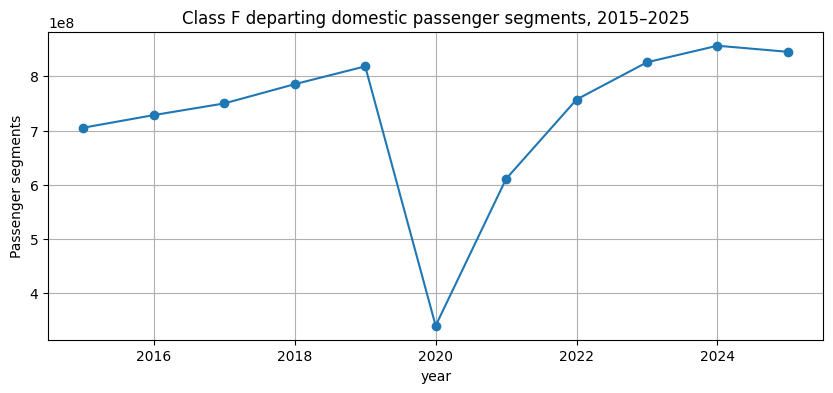

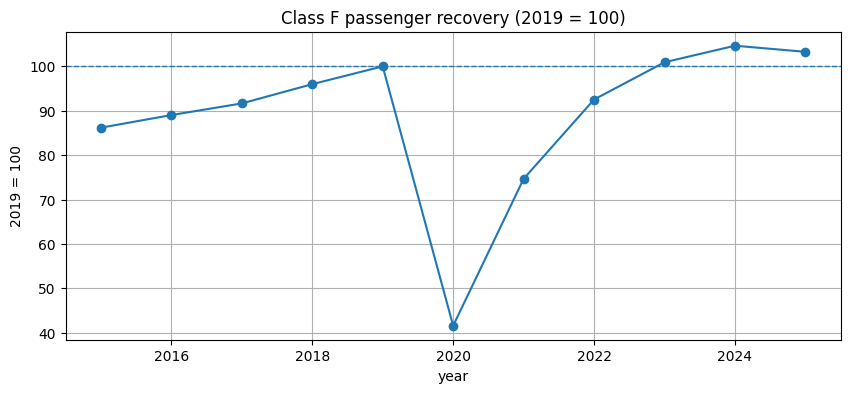

In [38]:
# National annual comparisons, using consistent 2015–2025 coverage.
annual_all = (analysis.groupby('year', as_index=False)
    .agg(passengers_all=('passengers','sum'), rows_all=('year','size'),
         seats_all=('seats','sum'), departures_all=('departures_performed','sum')))
annual_f = (f.groupby('year', as_index=False)
    .agg(passengers_F=('passengers','sum'), rows_F=('year','size'),
         seats_F=('seats','sum'), departures_F=('departures_performed','sum')))
annual_comparison = annual_all.merge(annual_f, on='year', validate='one_to_one')
annual_comparison['class_F_passenger_share_pct'] = (100 * annual_comparison.passengers_F /
                                                  annual_comparison.passengers_all)
baseline_value = annual_comparison.loc[annual_comparison.year.eq(2019),'passengers_F']
if len(baseline_value) != 1 or baseline_value.iloc[0] <= 0:
    raise ValueError('Expected exactly one positive Class F 2019 baseline')
annual_comparison['passenger_index_2019_100'] = (100 * annual_comparison.passengers_F /
                                                 baseline_value.iloc[0])
annual_comparison['passenger_change_yoy_pct'] = annual_comparison.passengers_F.pct_change() * 100
display(annual_comparison.round(2))
ax = annual_comparison.plot(x='year', y='passengers_F', kind='line', marker='o',
    figsize=(10,4), title='Class F departing domestic passenger segments, 2015–2025',
    legend=False, grid=True)
ax.set_ylabel('Passenger segments')
ax = annual_comparison.plot(x='year', y='passenger_index_2019_100', kind='line',
    marker='o', figsize=(10,4), title='Class F passenger recovery (2019 = 100)',
    legend=False, grid=True)
ax.axhline(100, linestyle='--', linewidth=1)
ax.set_ylabel('2019 = 100')

**Preliminary observations (from the saved full-year T-100 results):**

- Class F departing segments rose from **705.3 million (2015)** to **818.4 million (2019)**.
- They fell to **340.2 million in 2020**, a **58.4% decrease** from 2019.
- The 2019 recovery index reached **100.9 in 2023** and **103.3 in 2025**.
- Although above the 2019 baseline, Class F activity declined **1.3% from 2024 to 2025**.

These descriptive patterns motivate a shared 2019 reference line and airport-level drill-down for Q2. They do not, on their own, identify the causes of changes in traffic.

In [39]:
# Origin airport × year; additive measures for scheduled passenger service only.
airport_year = f.groupby(['year','airport_id'], as_index=False)[MEASURES].sum()
labels = (f.sort_values('year').drop_duplicates(['year','airport_id'], keep='last')
          [['year','airport_id','airport','city','state']])
airport_year = airport_year.merge(labels, on=['year','airport_id'], how='left', validate='one_to_one')
export('shared_airport_year_F', airport_year, ['year','airport_id'])


shared_airport_year_F: 8,182 rows, sample 100 rows


,year,airport_id,passengers,departures_performed,seats,freight_lb,mail_lb,airport,city,state
0,2015,10005,39.0,19.0,155.0,828.0,1900.0,05A,"Little Squaw, AK",AK
1,2015,10006,0.0,4.0,16.0,0.0,0.0,06A,"Kizhuyak, AK",AK
2,2015,10011,1106.0,143.0,1458.0,0.0,0.0,1G4,"Peach Springs, AZ",AZ
3,2015,10015,10.0,16.0,87.0,126.0,0.0,A02,"Deadmans Bay, AK",AK
4,2015,10016,0.0,1.0,9.0,0.0,0.0,A03,"Hallo Bay, AK",AK


,year,airport_id,passengers,departures_performed,seats,freight_lb,mail_lb,airport,city,state
0,2015,10005,39.0,19.0,155.0,828.0,1900.0,05A,"Little Squaw, AK",AK
1,2015,10006,0.0,4.0,16.0,0.0,0.0,06A,"Kizhuyak, AK",AK
2,2015,10011,1106.0,143.0,1458.0,0.0,0.0,1G4,"Peach Springs, AZ",AZ
3,2015,10015,10.0,16.0,87.0,126.0,0.0,A02,"Deadmans Bay, AK",AK
4,2015,10016,0.0,1.0,9.0,0.0,0.0,A03,"Hallo Bay, AK",AK
...,...,...,...,...,...,...,...,...,...,...
8177,2025,16603,1745.0,650.0,5180.0,0.0,0.0,DHB,"Deer Harbor, WA",WA
8178,2025,16755,2.0,1.0,9.0,0.0,0.0,T8X,"Dallas, TX",TX
8179,2025,16869,104945.0,2432.0,137746.0,0.0,0.0,XWA,"Williston, ND",ND
8180,2025,17011,8.0,5.0,36.0,370.0,0.0,6AK,"Newtok, AK",AK


,year,airport_id,passengers,departures_performed,seats,freight_lb,mail_lb,airport,city,state
7487,2025,10397,44231071.0,345195.0,53736049.0,59787347.0,3034537.0,ATL,"Atlanta, GA",GA
7602,2025,11292,37693948.0,323204.0,46411405.0,38690078.0,4324598.0,DEN,"Denver, CO",CO
7603,2025,11298,35110013.0,312298.0,42550760.0,37608346.0,4468268.0,DFW,"Dallas/Fort Worth, TX",TX
7939,2025,13930,33567189.0,360669.0,41476929.0,32973613.0,13178225.0,ORD,"Chicago, IL",IL
7827,2025,12892,24889067.0,198252.0,30588382.0,221181428.0,14289140.0,LAX,"Los Angeles, CA",CA
7825,2025,12889,24794522.0,188118.0,31806839.0,14035505.0,15876.0,LAS,"Las Vegas, NV",NV
7868,2025,13204,23988094.0,165468.0,29403702.0,11469225.0,6551.0,MCO,"Orlando, FL",FL
7964,2025,14107,23766925.0,202656.0,30146365.0,16015015.0,1251491.0,PHX,"Phoenix, AZ",AZ
7572,2025,11057,23617320.0,243118.0,29704636.0,11465486.0,1615934.0,CLT,"Charlotte, NC",NC
8045,2025,14747,22026535.0,183973.0,26701635.0,54021443.0,6534084.0,SEA,"Seattle, WA",WA


<Axes: title={'center': 'Top 10 Airports by Departing Passengers (2025)'}, xlabel='airport'>

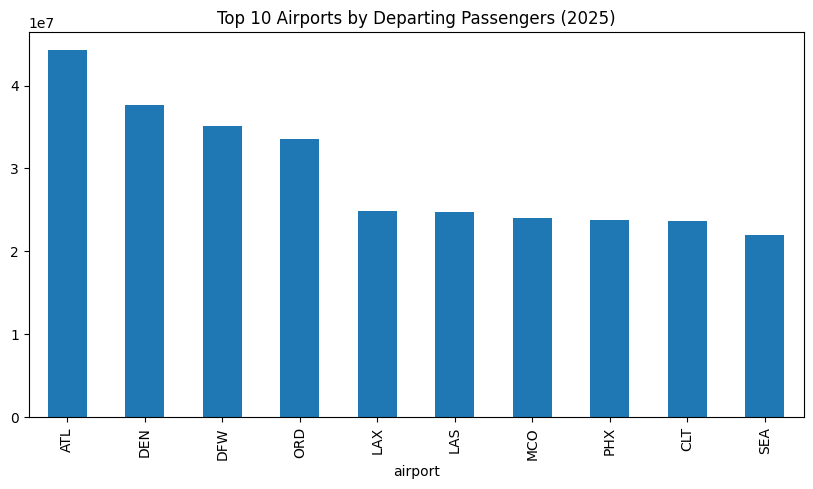

In [40]:
top_airports = (
    airport_year[airport_year['year'] == 2025]
    .sort_values('passengers', ascending=False)
    .head(10)
)

display(top_airports)

top_airports.plot(
    x='airport',
    y='passengers',
    kind='bar',
    title='Top 10 Airports by Departing Passengers (2025)',
    figsize=(10, 5),
    legend=False
)

## Q1. How did airport and carrier traffic rankings change from 2015 to 2025?

**Data and transformation:** Use the 2015–2025 T-100 segment records. Aggregate passengers, freight (pounds), and mail (pounds) separately by `year × airport`, `year × carrier`, and `year × airport × carrier`. Rank each metric **within each year**. Produce airport rankings for both all service classes and scheduled passenger Class F; carrier and airport-carrier tables currently represent all classes.

**Processed tables:** `q1_airports_year_all_classes.csv`, `q1_airports_year_F.csv`, `q1_carriers_year.csv`, `q1_airport_carrier_year.csv`.

**Preliminary observation:** The saved 2025 Class F airport summary ranks **ATL, DEN, and DFW** highest by departing passenger segments. Rankings may change when the metric switches from passengers to freight or mail; those quantities have different units and should never be combined into a single unvalidated payload measure.

**Proposed visualization for team sketch:** Two linked horizontal rankings (airports and carriers) with a year selector and metric selector; clicking an airport reveals carrier contributions. Label each chart's service-class scope explicitly.

**Revision since the proposal:** The earlier 2025-only ranking was expanded to **annual rankings from 2015 through 2025**. Airport, carrier, and drill-down totals represent overlapping views and must not be added together.

In [41]:
def q1_rank(frame, group_cols, scope):
    tmp = (
        frame.loc[frame.year.between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)]
        .groupby(group_cols, as_index=False)[['passengers', 'freight_lb', 'mail_lb']]
        .sum()
    )
    if tmp.empty:
        return tmp

    # Rank within each year, not across all years together
    for c in ['passengers', 'freight_lb', 'mail_lb']:
        ranked = tmp.groupby('year')[c].rank(method='min', ascending=False)
        tmp[c + '_rank'] = ranked.where(tmp[c].gt(0)).astype('Int64')

    tmp['scope'] = scope
    return tmp


# Airport labels by year
airport_names = (
    master.loc[master.year.between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)]
    .sort_values(['year', 'airport'])
    .drop_duplicates(['year', 'airport_id'])
    [['year', 'airport_id', 'airport', 'city', 'state']]
)

# Carrier labels by year
carrier_labels = (
    master.loc[master.year.between(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR)]
    .sort_values(['year', 'carrier_code'])
    .drop_duplicates(['year', 'carrier_id'])
    [['year', 'carrier_id', 'carrier_code']]
)

# Q1: airport rankings, all classes
q1_airports_all = q1_rank(master, ['year', 'airport_id'], 'all_classes')
q1_airports_all = q1_airports_all.merge(
    airport_names, on=['year', 'airport_id'], how='left', validate='one_to_one'
)
export('q1_airports_year_all_classes', q1_airports_all, ['year', 'passengers_rank'])

# Q1: airport rankings, F only
q1_airports_F = q1_rank(f, ['year', 'airport_id'], 'F_only')
q1_airports_F = q1_airports_F.merge(
    airport_names, on=['year', 'airport_id'], how='left', validate='one_to_one'
)
export('q1_airports_year_F', q1_airports_F, ['year', 'passengers_rank'])

# Q1: carrier rankings
q1_carriers = q1_rank(master, ['year', 'carrier_id'], 'all_classes')
q1_carriers = q1_carriers.merge(
    carrier_labels, on=['year', 'carrier_id'], how='left', validate='one_to_one'
)
export('q1_carriers_year', q1_carriers, ['year', 'passengers_rank'])

# Q1: airport x carrier drilldown
q1_airport_carrier = q1_rank(master, ['year', 'airport_id', 'carrier_id'], 'all_classes')
q1_airport_carrier = q1_airport_carrier.merge(
    airport_names, on=['year', 'airport_id'], how='left', validate='many_to_one'
).merge(
    carrier_labels, on=['year', 'carrier_id'], how='left', validate='many_to_one'
)
export('q1_airport_carrier_year', q1_airport_carrier, ['year', 'airport_id', 'passengers_rank'])

q1_airports_year_all_classes: 14,126 rows, sample 100 rows


,year,airport_id,passengers,freight_lb,mail_lb,passengers_rank,freight_lb_rank,mail_lb_rank,scope,airport,city,state
76,2015,10397,44337065.0,274568107.0,46760620.0,1,15,6,all_classes,ATL,"Atlanta, GA",GA
783,2015,13930,30673411.0,355042911.0,55822868.0,2,11,4,all_classes,ORD,"Chicago, IL",IL
248,2015,11298,27933882.0,366994209.0,34678851.0,3,10,11,all_classes,DFW,"Dallas/Fort Worth, TX",TX
587,2015,12892,26874558.0,788643108.0,72341572.0,4,5,3,all_classes,LAX,"Los Angeles, CA",CA
246,2015,11292,25540178.0,213960542.0,21936378.0,5,18,17,all_classes,DEN,"Denver, CO",CO


q1_airports_year_F: 8,182 rows, sample 100 rows


,year,airport_id,passengers,freight_lb,mail_lb,passengers_rank,freight_lb_rank,mail_lb_rank,scope,airport,city,state
54,2015,10397,44319480.0,77643232.0,46743502.0,1,3,4,F_only,ATL,"Atlanta, GA",GA
530,2015,13930,30661978.0,37990387.0,53903369.0,2,9,2,F_only,ORD,"Chicago, IL",IL
175,2015,11298,27914397.0,45641057.0,18105164.0,3,7,12,F_only,DFW,"Dallas/Fort Worth, TX",TX
416,2015,12892,26854824.0,178889410.0,59070551.0,4,1,1,F_only,LAX,"Los Angeles, CA",CA
174,2015,11292,25521201.0,24614260.0,20337428.0,5,15,11,F_only,DEN,"Denver, CO",CO


q1_carriers_year: 1,276 rows, sample 100 rows


,year,carrier_id,passengers,freight_lb,mail_lb,passengers_rank,freight_lb_rank,mail_lb_rank,scope,carrier_code
0,2015,19393.0,147830237.0,319447454.0,0.0,1,6,<NA>,all_classes,WN
4,2015,19790.0,115567285.0,255286474.0,191424562.0,2,7,3,all_classes,DL
5,2015,19805.0,94086042.0,193615065.0,94559049.0,3,10,4,all_classes,AA
9,2015,19977.0,69811835.0,196991792.0,274142097.0,4,9,1,all_classes,UA
75,2015,20409.0,28934891.0,21013437.0,0.0,5,23,<NA>,all_classes,B6


q1_airport_carrier_year: 92,693 rows, sample 100 rows


,year,airport_id,carrier_id,passengers,freight_lb,mail_lb,passengers_rank,freight_lb_rank,mail_lb_rank,scope,airport,city,state,carrier_code
0,2015,10005,20408.0,184.0,11251.0,3516.0,3996,2076,877,all_classes,05A,"Little Squaw, AK",AK,5V
1,2015,10006,20443.0,1.0,0.0,0.0,6189,<NA>,<NA>,all_classes,06A,"Kizhuyak, AK",AK,2O
2,2015,10008,20439.0,15.0,0.0,0.0,5523,<NA>,<NA>,all_classes,08A,"Elizabeth Island, AK",AK,HB
3,2015,10011,20424.0,37235.0,0.0,0.0,1409,<NA>,<NA>,all_classes,1G4,"Peach Springs, AZ",AZ,YR
4,2015,10011,21236.0,4869.0,0.0,0.0,2308,<NA>,<NA>,all_classes,1G4,"Peach Springs, AZ",AZ,0JQ


,year,airport_id,carrier_id,passengers,freight_lb,mail_lb,passengers_rank,freight_lb_rank,mail_lb_rank,scope,airport,city,state,carrier_code
0,2015,10005,20408.0,184.0,11251.0,3516.0,3996,2076,877,all_classes,05A,"Little Squaw, AK",AK,5V
1,2015,10006,20443.0,1.0,0.0,0.0,6189,<NA>,<NA>,all_classes,06A,"Kizhuyak, AK",AK,2O
2,2015,10008,20439.0,15.0,0.0,0.0,5523,<NA>,<NA>,all_classes,08A,"Elizabeth Island, AK",AK,HB
3,2015,10011,20424.0,37235.0,0.0,0.0,1409,<NA>,<NA>,all_classes,1G4,"Peach Springs, AZ",AZ,YR
4,2015,10011,21236.0,4869.0,0.0,0.0,2308,<NA>,<NA>,all_classes,1G4,"Peach Springs, AZ",AZ,0JQ
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92688,2025,17075,21080.0,6.0,0.0,0.0,5642,<NA>,<NA>,all_classes,JVI,"Manville, NJ",NJ,TJ
92689,2025,17078,21618.0,1.0,0.0,0.0,6246,<NA>,<NA>,all_classes,IL4,"Pittsfield, IL",IL,9X
92690,2025,17079,21080.0,13.0,0.0,0.0,5288,<NA>,<NA>,all_classes,N40,"Pittstown, NJ",NJ,TJ
92691,2025,17155,21894.0,8.0,0.0,0.0,5509,<NA>,<NA>,all_classes,ANW,"Ainsworth, NE",NE,AN


## Q2. How did scheduled passenger traffic and capacity recover relative to 2019?

**Data and transformation:** Using Class F, sum passenger segments, performed departures, and seats by `year` and by `airport × year`. Compute each measure's index as `100 × value / 2019 value`. Airport-level recovery uses each airport's **own** 2019 baseline; missing or zero baselines yield undefined indices.

**Processed tables:** `q2_national_year_F.csv`, `q2_airport_year_F.csv`.

**Preliminary observation:** National Class F passenger activity was **41.6% of its 2019 level in 2020** and **103.3% in 2025**. Recovery indices make it possible to compare quantities with different raw units without suggesting that passengers, seats, and departures are interchangeable.

**Proposed visualization for team sketch:** A line chart with year on the horizontal axis, recovery index on the vertical axis, and separate encodings for passengers, seats, and performed departures. Include a horizontal reference at **100** and an airport selector.

**Limitation:** Annual indices show relative recovery, not a causal explanation of disruptions or airport-specific operating conditions.

In [42]:
def with_index(frame, keys, values, baseline=2019):
    out = frame.copy()
    if keys:
        base = out[out.year.eq(baseline)][keys+values].rename(columns={v:f'{v}_baseline' for v in values})
        out = out.merge(base, on=keys, how='left', validate='many_to_one')
    else:
        bb = out[out.year.eq(baseline)]
        for v in values: out[f'{v}_baseline'] = bb[v].iloc[0] if len(bb) else np.nan
    for v in values:
        denom = out[f'{v}_baseline'].replace(0, np.nan)
        out[f'{v}_index_2019'] = 100*out[v]/denom
    return out
q2_airport = with_index(airport_year, ['airport_id'], ['passengers','departures_performed','seats'])
q2_national = with_index(airport_year.groupby('year',as_index=False)[['passengers','departures_performed','seats']].sum(), [], ['passengers','departures_performed','seats'])
export('q2_airport_year_F', q2_airport, ['airport_id','year'])
export('q2_national_year_F', q2_national, ['year'])

q2_airport_year_F: 8,182 rows, sample 100 rows


,year,airport_id,passengers,departures_performed,seats,freight_lb,mail_lb,airport,city,state,passengers_baseline,departures_performed_baseline,seats_baseline,passengers_index_2019,departures_performed_index_2019,seats_index_2019
0,2015,10005,39.0,19.0,155.0,828.0,1900.0,05A,"Little Squaw, AK",AK,1.0,2.0,18.0,3900.0,950.0,861.111111
787,2016,10005,3.0,3.0,15.0,89.0,0.0,05A,"Little Squaw, AK",AK,1.0,2.0,18.0,300.0,150.0,83.333333
1553,2017,10005,2.0,3.0,27.0,1003.0,0.0,05A,"Little Squaw, AK",AK,1.0,2.0,18.0,200.0,150.0,150.000000
3075,2019,10005,1.0,2.0,18.0,137.0,286.0,05A,"Little Squaw, AK",AK,1.0,2.0,18.0,100.0,100.0,100.000000
1,2015,10006,0.0,4.0,16.0,0.0,0.0,06A,"Kizhuyak, AK",AK,NaN,NaN,NaN,NaN,NaN,NaN


q2_national_year_F: 11 rows, sample 11 rows


,year,passengers,departures_performed,seats,passengers_baseline,departures_performed_baseline,seats_baseline,passengers_index_2019,departures_performed_index_2019,seats_index_2019
0,2015,705333022.0,8059689.0,854251386.0,818425865.0,8594870.0,992344460.0,86.181663,93.773251,86.084159
1,2016,728600334.0,8183844.0,891798527.0,818425865.0,8594870.0,992344460.0,89.024598,95.217775,89.867840
2,2017,750077053.0,8176047.0,917331095.0,818425865.0,8594870.0,992344460.0,91.648747,95.127058,92.440794
3,2018,785574495.0,8398404.0,958559533.0,818425865.0,8594870.0,992344460.0,95.986030,97.714148,96.595444
4,2019,818425865.0,8594870.0,992344460.0,818425865.0,8594870.0,992344460.0,100.000000,100.000000,100.000000


,year,passengers,departures_performed,seats,passengers_baseline,departures_performed_baseline,seats_baseline,passengers_index_2019,departures_performed_index_2019,seats_index_2019
0,2015,705333022.0,8059689.0,8.542514e+08,818425865.0,8594870.0,992344460.0,86.181663,93.773251,86.084159
1,2016,728600334.0,8183844.0,8.917985e+08,818425865.0,8594870.0,992344460.0,89.024598,95.217775,89.867840
2,2017,750077053.0,8176047.0,9.173311e+08,818425865.0,8594870.0,992344460.0,91.648747,95.127058,92.440794
3,2018,785574495.0,8398404.0,9.585595e+08,818425865.0,8594870.0,992344460.0,95.986030,97.714148,96.595444
4,2019,818425865.0,8594870.0,9.923445e+08,818425865.0,8594870.0,992344460.0,100.000000,100.000000,100.000000
5,2020,340210569.0,5212074.0,5.986498e+08,818425865.0,8594870.0,992344460.0,41.568893,60.641685,60.326812
6,2021,611010452.0,6758387.0,8.030615e+08,818425865.0,8594870.0,992344460.0,74.656787,78.632801,80.925681
7,2022,757268029.0,7423458.0,9.252603e+08,818425865.0,8594870.0,992344460.0,92.527382,86.370800,93.239829
8,2023,825979065.0,7808050.0,1.018843e+09,818425865.0,8594870.0,992344460.0,100.922894,90.845469,102.670324
9,2024,856457490.0,8137408.0,1.054338e+09,818425865.0,8594870.0,992344460.0,104.646924,94.677499,106.247173


## Q3. How does domestic air traffic compare with state population?

**Data and transformation:** Read the two original Census files in the notebook: `nst-est2020int-pop.xlsx` (**2015–2019**) and `NST-EST2025-ALLDATA.csv` (**2020–2025**). Standardize state/year/population, combine them, and join to Class F departing passenger segments aggregated by **origin state × year**. Calculate `departing_segments_per_resident = passengers / population`.

**Processed tables:** `q3_state_population_2015_2025.csv`, `q3_state_year_airport_activity.csv`, `q3_state_year.csv`.

**Preliminary observation:** The saved run produced **561 state-year population records** (50 states and DC for eleven years) and matched population to **all 546 state-year airport-activity rows** present in the T-100 aggregation.

**Proposed visualization for team sketch:** A year-filtered U.S. state choropleth for departing segments per resident, accompanied by a ranked state chart or population-versus-traffic scatter plot. Provide a legend with explicit ratio units.

**Revision since the proposal:** This replaces the original Atlanta metropolitan-area question with a **state-level comparison**. The ratio does **not** estimate the share of residents who fly: connecting travelers and out-of-state travelers contribute segments. Territories are excluded. The Census estimate series changes at 2019/2020, limiting strict cross-boundary trend comparisons.

In [43]:
# Q3: state-year departure activity across all origin airports, scheduled passenger Class F.
# Use the airport-year table, so each origin airport contributes once per year.
state_base = airport_year.loc[airport_year.state.notna()].copy()
state_base['state'] = state_base['state'].astype('string').str.strip().str.upper()
state_base = state_base.loc[state_base.state.str.fullmatch(r'[A-Z]{2}', na=False)].copy()
# Limit Q3 to the 50 states + DC (territorial codes such as PR, VI and TT excluded).
STATE_CODES = set('AL AK AZ AR CA CO CT DE DC FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY'.split())
excluded_territories = state_base.loc[~state_base.state.isin(STATE_CODES)]
print(f'Q3: excluding {len(excluded_territories):,} origin airport-year rows outside the 50 states and DC.')
state_base = state_base.loc[state_base.state.isin(STATE_CODES)].copy()
q3_activity = (state_base.groupby(['state','year'], as_index=False)
               .agg(passengers=('passengers','sum'),
                    departures_performed=('departures_performed','sum'),
                    seats=('seats','sum'),
                    airport_count=('airport_id','nunique')))
export('q3_state_year_airport_activity', q3_activity, ['state','year'])

# Census state name -> USPS state code. Fixed list makes the join traceable.
state_names = [
    'Alabama','Alaska','Arizona','Arkansas','California','Colorado','Connecticut',
    'Delaware','District of Columbia','Florida','Georgia','Hawaii','Idaho','Illinois',
    'Indiana','Iowa','Kansas','Kentucky','Louisiana','Maine','Maryland','Massachusetts',
    'Michigan','Minnesota','Mississippi','Missouri','Montana','Nebraska','Nevada',
    'New Hampshire','New Jersey','New Mexico','New York','North Carolina','North Dakota',
    'Ohio','Oklahoma','Oregon','Pennsylvania','Rhode Island','South Carolina',
    'South Dakota','Tennessee','Texas','Utah','Vermont','Virginia','Washington',
    'West Virginia','Wisconsin','Wyoming'
]
state_codes = [
    'AL','AK','AZ','AR','CA','CO','CT','DE','DC','FL','GA','HI','ID','IL','IN','IA',
    'KS','KY','LA','ME','MD','MA','MI','MN','MS','MO','MT','NE','NV','NH','NJ','NM',
    'NY','NC','ND','OH','OK','OR','PA','RI','SC','SD','TN','TX','UT','VT','VA','WA',
    'WV','WI','WY'
]
name_to_code = dict(zip(state_names, state_codes))
assert len(name_to_code) == 51

old_census_path = CENSUS_DIR / 'nst-est2020int-pop.xlsx'
new_census_path = CENSUS_DIR / 'NST-EST2025-ALLDATA.csv'
for census_path in (old_census_path, new_census_path):
    if not census_path.is_file():
        raise FileNotFoundError(
            f'Missing Census file: {census_path}. Put both Census files in Census Data/.')

# The intercensal workbook has descriptive text rows above the state table.
# The first column contains state names, and Excel columns H–L contain 2015–2019.
intercensal = pd.read_excel(old_census_path, sheet_name=0, header=None)
intercensal_records = []
for record in intercensal.itertuples(index=False, name=None):
    name = str(record[0]).strip().lstrip('.').strip() if pd.notna(record[0]) else ''
    if name not in name_to_code:
        continue
    for col_idx, year in zip(range(7, 12), range(2015, 2020)):
        value = pd.to_numeric(record[col_idx], errors='coerce')
        if pd.isna(value) or value <= 0:
            raise ValueError(f'Invalid 2015–2019 population for {name}, {year}: {record[col_idx]}')
        intercensal_records.append({
            'state': name_to_code[name], 'year': year, 'population': int(value),
            'population_series': '2010-2020 intercensal (Nov 2024)', 'state_name': name
        })

# Read the 2025-vintage file with SUMLEV as text to preserve leading zeros (040).
latest = pd.read_csv(new_census_path, dtype={'SUMLEV': 'string'}, encoding='utf-8-sig')
latest['NAME'] = latest['NAME'].astype('string').str.strip()
latest = latest[latest['SUMLEV'].str.zfill(3).eq('040') & latest['NAME'].isin(name_to_code)]
if len(latest) != 51:
    raise ValueError(f'Expected 51 state/DC rows in 2025-vintage Census file, found {len(latest)}')
latest_records = []
for record in latest.to_dict('records'):
    for year in range(2020, 2026):
        value = pd.to_numeric(record[f'POPESTIMATE{year}'], errors='coerce')
        if pd.isna(value) or value <= 0:
            raise ValueError(f'Invalid 2020–2025 population for {record["NAME"]}, {year}')
        latest_records.append({
            'state': name_to_code[record['NAME']], 'year': year,
            'population': int(value), 'population_series': '2025 vintage (NST-EST2025)',
            'state_name': record['NAME']
        })

state_pop = (pd.DataFrame(intercensal_records + latest_records)
             .sort_values(['state', 'year']).reset_index(drop=True))
assert len(state_pop) == 561, f'Expected 561 state/year population rows, got {len(state_pop)}'
assert not state_pop.duplicated(['state','year']).any(), 'Duplicate state/year population keys'
assert set(state_pop.year) == set(range(2015, 2026))
assert set(state_pop.state) == set(state_codes)
assert state_pop.population.gt(0).all()
export('q3_state_population_2015_2025', state_pop, ['state','year'])

q3_state = q3_activity.merge(state_pop, on=['state','year'], how='left', validate='one_to_one')
q3_state['population_matched'] = q3_state.population.notna()
q3_state['departing_segments_per_resident'] = q3_state.passengers / q3_state.population
assert q3_state.population_matched.all(), 'Missing state/year population: check source files and codes'
assert len(q3_state) == len(q3_activity), 'Unexpected population join duplication'
export('q3_state_year', q3_state, ['state','year'])
print(f'Q3 population matches: {q3_state.population_matched.sum():,}/{len(q3_state):,} state-years.')


Q3: excluding 186 origin airport-year rows outside the 50 states and DC.
q3_state_year_airport_activity: 546 rows, sample 100 rows


,state,year,passengers,departures_performed,seats,airport_count
0,AK,2015,5220553.0,370167.0,8526376.0,272
1,AK,2016,5269896.0,371407.0,8770289.0,259
2,AK,2017,5283938.0,336272.0,8547611.0,265
3,AK,2018,5407900.0,337659.0,8882168.0,252
4,AK,2019,5465107.0,329889.0,8758819.0,247


q3_state_population_2015_2025: 561 rows, sample 100 rows


,state,year,population,population_series,state_name
0,AK,2015,739120,2010-2020 intercensal (Nov 2024),Alaska
1,AK,2016,743397,2010-2020 intercensal (Nov 2024),Alaska
2,AK,2017,741937,2010-2020 intercensal (Nov 2024),Alaska
3,AK,2018,737710,2010-2020 intercensal (Nov 2024),Alaska
4,AK,2019,734820,2010-2020 intercensal (Nov 2024),Alaska


q3_state_year: 546 rows, sample 100 rows


,state,year,passengers,departures_performed,seats,airport_count,population,population_series,state_name,population_matched,departing_segments_per_resident
0,AK,2015,5220553.0,370167.0,8526376.0,272,739120,2010-2020 intercensal (Nov 2024),Alaska,True,7.063201
1,AK,2016,5269896.0,371407.0,8770289.0,259,743397,2010-2020 intercensal (Nov 2024),Alaska,True,7.088939
2,AK,2017,5283938.0,336272.0,8547611.0,265,741937,2010-2020 intercensal (Nov 2024),Alaska,True,7.121815
3,AK,2018,5407900.0,337659.0,8882168.0,252,737710,2010-2020 intercensal (Nov 2024),Alaska,True,7.330658
4,AK,2019,5465107.0,329889.0,8758819.0,247,734820,2010-2020 intercensal (Nov 2024),Alaska,True,7.437341


Q3 population matches: 546/546 state-years.


## Q4. How has outbound nonstop connectivity changed across airports?

**Data and transformation:** Restrict T-100 to Class F and group performed departures by `year × origin airport × destination airport`. Count distinct destinations for each origin-year after requiring at least **one performed departure** on the route. Compare each airport's destination count with its 2015 value.

**Processed tables:** `q4_routes.csv`, `q4_destinations_airport_year.csv`.

**Preliminary observation:** See the route-level summary below. This metric counts **reported nonstop destinations**, not the number of daily flights or the quality of service.

**Proposed visualization for team sketch:** Selected-airport time series for destination counts, paired with a route map for a chosen year. Provide an airport selector and explain the minimum-departures rule.

**Limitation:** With the current one-departure threshold, an occasional or seasonal route can count as connectivity. A stricter service-frequency threshold should be tested before interpreting routes as consistently available.

In [44]:
MIN_ROUTE_DEPARTURES = 1
if not raw.empty:
    rr = f[f.airport_id.notna() & f.dest_airport_id.notna()].copy()
    q4_routes = rr.groupby(['year','airport_id','dest_airport_id'],as_index=False).agg(
        departures_performed=('departures_performed','sum'), passengers=('passengers','sum'))
    q4_routes = q4_routes[q4_routes.departures_performed >= MIN_ROUTE_DEPARTURES]
    q4_count = q4_routes.groupby(['year','airport_id'],as_index=False).agg(nonstop_destinations=('dest_airport_id','nunique'))
    base = q4_count[q4_count.year.eq(2015)][['airport_id','nonstop_destinations']].rename(columns={'nonstop_destinations':'baseline_2015_destinations'})
    q4_count = q4_count.merge(base,on='airport_id',how='left')
    q4_count['change_from_2015'] = q4_count.nonstop_destinations-q4_count.baseline_2015_destinations
    q4_count['percent_change_from_2015'] = 100*q4_count.change_from_2015/q4_count.baseline_2015_destinations.replace(0,np.nan)
    export('q4_routes',q4_routes,['year','airport_id','dest_airport_id'])
    export('q4_destinations_airport_year',q4_count,['airport_id','year'])
else:
    print('Q4 BLOCKED: destination columns were removed from supplied master.')

q4_routes: 159,975 rows, sample 100 rows


,year,airport_id,dest_airport_id,departures_performed,passengers
0,2015,10005,10299,1.0,3.0
1,2015,10005,10349,4.0,3.0
2,2015,10005,11214,1.0,1.0
3,2015,10005,11630,11.0,30.0
4,2015,10005,11833,1.0,1.0


q4_destinations_airport_year: 8,175 rows, sample 100 rows


,year,airport_id,nonstop_destinations,baseline_2015_destinations,change_from_2015,percent_change_from_2015
0,2015,10005,6,6.0,0.0,0.000000
786,2016,10005,2,6.0,-4.0,-66.666667
1552,2017,10005,1,6.0,-5.0,-83.333333
3072,2019,10005,2,6.0,-4.0,-66.666667
1,2015,10006,1,1.0,0.0,0.000000


**Preliminary observations (processed Q4 tables):** The median distinct destinations among qualifying origin airports increased from **7 in 2015** to **8 in 2025**; the corresponding mean increased from approximately **18.8 to 22.3**. However, qualifying origin airports changed from **786 to 742**, so this is a comparison of each year's airport population, not a matched-airport growth estimate.

**Design implication:** Combine a summary of overall connectivity with airport-specific trends. A route map helps explain which destinations contribute to a selected airport's count; the same airport filters should apply across views.

## Q5. How is domestic passenger activity distributed across airport sizes?

**Data and transformation:** Assign airports to Small, Medium, or Large according to terciles of their **2019 Class F departing passenger volumes**; retain those labels in subsequent years. Airports without a 2019 baseline are reported separately. Calculate group passenger totals/shares by year and the annual national share of the **ten largest airports in that year**.

**Processed tables:** `q5_airport_size_assignments.csv`, `q5_size_group_year.csv`, `q5_top10_concentration.csv`.

**Preliminary observation:** The airport-size terciles divide the **number of airports**, not passenger traffic. Accordingly, the Large group contains nearly all passenger segments, making a single passenger-share stack difficult to read.

**Proposed visualization for team sketch:** Separate displays for (1) number of airports by size category and (2) passenger share or top-ten concentration over time. Consider a log-scale distribution chart to reveal smaller airports.

**Limitation:** These are **project-defined categories**, not FAA hub designations. The top-ten measure is recalculated annually and does not track a fixed list of airports.

In [45]:
baseline = airport_year.loc[airport_year.year.eq(2019),['airport_id','passengers']].rename(columns={'passengers':'passengers_2019'})
positive = baseline.loc[baseline.passengers_2019.gt(0),'passengers_2019']
cut1,cut2 = positive.quantile([1/3,2/3]).values
if cut1 == cut2: cut2 = cut1 + 1
baseline['size_group'] = np.select([baseline.passengers_2019.le(cut1), baseline.passengers_2019.le(cut2)],
                                    ['Small','Medium'],default='Large')
q5_airport = airport_year.merge(baseline,on='airport_id',how='left')
q5_airport['size_group'] = q5_airport.size_group.fillna('New/no 2019 baseline')
q5_groups = q5_airport.groupby(['year','size_group'],as_index=False).agg(
    airport_count=('airport_id','nunique'),passengers=('passengers','sum'))
national_totals = q5_airport.groupby('year')['passengers'].sum()
q5_groups['national_share_pct'] = 100*q5_groups.passengers / q5_groups.year.map(national_totals)
q5_groups = with_index(q5_groups,['size_group'],['passengers'])
q5_top10 = (q5_airport.sort_values(['year','passengers'],ascending=[True,False])
            .groupby('year',group_keys=False).head(10).groupby('year')['passengers'].sum()
            .div(national_totals).mul(100).rename('top_10_airports_share_pct').reset_index())
export('q5_airport_size_assignments',baseline,['airport_id'])
export('q5_size_group_year',q5_groups,['year','size_group'])
export('q5_top10_concentration',q5_top10,['year'])
print(f'2019 cutoffs (departing passengers): <= {cut1:,.0f} Small; <= {cut2:,.0f} Medium; > {cut2:,.0f} Large')

q5_airport_size_assignments: 731 rows, sample 100 rows


,airport_id,passengers_2019,size_group
3075,10005,1.0,Small
3076,10042,1.0,Small
3077,10056,317.0,Small
3078,10063,1.0,Small
3079,10135,437600.0,Large


q5_size_group_year: 43 rows, sample 43 rows


,year,size_group,airport_count,passengers,national_share_pct,passengers_baseline,passengers_index_2019
0,2015,Large,237,698984178.0,99.099880,811619405.0,86.122162
1,2015,Medium,229,5757018.0,0.816213,6488265.0,88.729699
2,2015,New/no 2019 baseline,105,168087.0,0.023831,NaN,NaN
3,2015,Small,216,423739.0,0.060076,318195.0,133.169597
4,2016,Large,237,722348102.0,99.141885,811619405.0,89.000842


q5_top10_concentration: 11 rows, sample 11 rows


,year,top_10_airports_share_pct
0,2015,36.024393
1,2016,35.977114
2,2017,35.587127
3,2018,34.966444
4,2019,34.984923


2019 cutoffs (departing passengers): <= 4,520 Small; <= 101,483 Medium; > 101,483 Large


**Preliminary observations (processed Q5 tables):** The Large group accounted for approximately **99.17% of Class F departing passenger segments in 2019** and **99.11% in 2025**. The ten largest airports accounted for approximately **36.02% in 2015**, **34.98% in 2019**, and **34.75% in 2025**.

**Design implication:** Show airport **counts** and passenger **volumes/shares** in separate charts, rather than relying solely on a 100% stacked area chart that would obscure the Small and Medium groups. Note airports without a 2019 size label.

## Q6. How do on-time performance and delays vary by airport, carrier, and month?

**Data and transformation:** Read raw BTS On-Time Performance CSVs recursively from `data/On-Time Performance/` (or `On-Time Performance/`). Process each file in chunks and aggregate by `year × month × origin airport ID × reporting-carrier ID`, then roll up to airport/month, airport/year, and airport/carrier/year. The approach avoids loading all flight-level records simultaneously.

**Metrics:** Reported flights, eligible flights with valid delays, cancellation/diversion counts, on-time arrival rate (`ArrDelay < 15` minutes), and average signed arrival/departure delay. Retain delay **sums and valid-flight counts** for correct weighted rollups. Reported delay-cause minutes are descriptive and should not be treated as mutually exclusive without verification.

**Processed tables:** `q6_month_coverage.csv`, `q6_airport_carrier_month.csv`, `q6_airport_month.csv`, `q6_airport_carrier_year.csv`, `q6_airport_year.csv`, and `q6_airport_year_complete.csv`.

**Proposed visualization for team sketch:** Airport-by-month heatmap of on-time arrivals, plus selectable carrier and year; include a coverage indicator so missing data are not confused with low performance.

**Interpretation and limitation:** An arrival delay is an outcome at the **destination** but is grouped under the **flight's origin** for comparison with T-100. BTS On-Time reporting carriers do not cover every T-100 service. A complete set of monthly files is not proof that each airport reported service in every month.

In [46]:
# Q6: memory-efficient, multi-file BTS On-Time Performance processing.
from collections import defaultdict

ONTIME_DIR_OPTIONS = [DATA_DIR / 'On-Time Performance', Path('On-Time Performance'), DATA_DIR / 'inputs' / 'On-Time Performance']
ONTIME_DIR = next((folder for folder in ONTIME_DIR_OPTIONS if folder.is_dir()), ONTIME_DIR_OPTIONS[0])
OTP_COLUMNS = ['Year','Month','OriginAirportID','DOT_ID_Reporting_Airline',
               'ArrDelay','DepDelay','Cancelled','Diverted',
               'CarrierDelay','WeatherDelay','NASDelay','SecurityDelay','LateAircraftDelay']
OTP_KEYS = ['year','month','airport_id','carrier_id']
OTP_ADDITIVE = ['reported_flights','valid_arrival_flights','valid_departure_flights',
                'ontime_arrivals','cancelled_flights','diverted_flights',
                'arrival_delay_sum','departure_delay_sum',
                'carrier_delay_min_sum','weather_delay_min_sum','nas_delay_min_sum',
                'security_delay_min_sum','late_aircraft_delay_min_sum']
OTP_CAUSES = {'CarrierDelay':'carrier_delay_min_sum','WeatherDelay':'weather_delay_min_sum',
              'NASDelay':'nas_delay_min_sum','SecurityDelay':'security_delay_min_sum',
              'LateAircraftDelay':'late_aircraft_delay_min_sum'}

def otp_chunk_rollup(chunk):
    chunk = chunk.rename(columns={'Year':'year','Month':'month','OriginAirportID':'airport_id',
                                  'DOT_ID_Reporting_Airline':'carrier_id'})
    for col in ['year','month','airport_id','carrier_id','ArrDelay','DepDelay','Cancelled','Diverted'] + list(OTP_CAUSES):
        chunk[col] = pd.to_numeric(chunk[col], errors='coerce')
    chunk = chunk.loc[chunk.year.between(ANALYSIS_START_YEAR,ANALYSIS_END_YEAR)
                      & chunk.month.between(1,12) & chunk.airport_id.notna() & chunk.carrier_id.notna()].copy()
    if chunk.empty:
        return pd.DataFrame(columns=OTP_KEYS+OTP_ADDITIVE)
    # Missing arrival/departure times are never interpreted as zero delay.
    completed = chunk.Cancelled.eq(0) & chunk.Diverted.eq(0)
    valid_arr = completed & chunk.ArrDelay.notna()
    valid_dep = chunk.Cancelled.eq(0) & chunk.DepDelay.notna()
    chunk['reported_flights'] = 1
    chunk['valid_arrival_flights'] = valid_arr.astype('int64')
    chunk['valid_departure_flights'] = valid_dep.astype('int64')
    chunk['ontime_arrivals'] = (valid_arr & chunk.ArrDelay.lt(15)).astype('int64')
    chunk['cancelled_flights'] = chunk.Cancelled.eq(1).astype('int64')
    chunk['diverted_flights'] = chunk.Diverted.eq(1).astype('int64')
    chunk['arrival_delay_sum'] = chunk.ArrDelay.where(valid_arr,0).fillna(0)
    chunk['departure_delay_sum'] = chunk.DepDelay.where(valid_dep,0).fillna(0)
    for source,target in OTP_CAUSES.items():
        chunk[target] = chunk[source].fillna(0)  # Cause totals are reported only on qualifying delayed flights.
    return chunk.groupby(OTP_KEYS,as_index=False,dropna=False)[OTP_ADDITIVE].sum()

def otp_add_rates(df):
    df = df.copy()
    df['avg_arrival_delay_min'] = df.arrival_delay_sum / df.valid_arrival_flights.replace(0,np.nan)
    df['avg_departure_delay_min'] = df.departure_delay_sum / df.valid_departure_flights.replace(0,np.nan)
    df['on_time_rate_pct'] = 100 * df.ontime_arrivals / df.valid_arrival_flights.replace(0,np.nan)
    df['cancellation_rate_pct'] = 100 * df.cancelled_flights / df.reported_flights.replace(0,np.nan)
    df['diversion_rate_pct'] = 100 * df.diverted_flights / df.reported_flights.replace(0,np.nan)
    return df

def otp_rollup(df, keys):
    if df.empty:
        return pd.DataFrame(columns=keys+OTP_ADDITIVE)
    return otp_add_rates(df.groupby(keys,as_index=False)[OTP_ADDITIVE].sum())

ontime_files = sorted(ONTIME_DIR.rglob('*.csv')) if ONTIME_DIR.is_dir() else []
# Ignore a previously exported summary accidentally stored in the input directory.
ontime_files = [p for p in ontime_files if not p.name.lower().startswith(('q6_','shared_'))]
q6_month_parts = []
coverage = set()
for file_path in ontime_files:
    print(f'Processing On-Time source: {file_path.name}')
    file_parts = []
    observed_months = set()
    for chunk in pd.read_csv(file_path, usecols=lambda col: col.strip() in OTP_COLUMNS,
                             chunksize=100_000, low_memory=False):
        missing = set(OTP_COLUMNS).difference(chunk.columns)
        if missing:
            raise ValueError(f'{file_path.name}: missing raw BTS fields: {sorted(missing)}')
        pairs = chunk[['Year','Month']].dropna().drop_duplicates()
        observed_months.update((int(y),int(m)) for y,m in pairs.itertuples(index=False,name=None)
                               if ANALYSIS_START_YEAR <= y <= ANALYSIS_END_YEAR and 1 <= m <= 12)
        part = otp_chunk_rollup(chunk)
        if not part.empty: file_parts.append(part)
    coverage.update(observed_months)
    if file_parts:
        q6_month_parts.append(pd.concat(file_parts,ignore_index=True).groupby(OTP_KEYS,as_index=False)[OTP_ADDITIVE].sum())

q6_month_coverage = pd.DataFrame([{'year':year,'month':month,'file_present':(year,month) in coverage}
    for year in range(ANALYSIS_START_YEAR, ANALYSIS_END_YEAR+1) for month in range(1,13)])
q6_year_coverage = q6_month_coverage.groupby('year',as_index=False).agg(months_present=('file_present','sum'))
q6_year_coverage['full_year_coverage'] = q6_year_coverage.months_present.eq(12)
export('q6_month_coverage',q6_month_coverage,['year','month'])
display(q6_year_coverage)

if q6_month_parts:
    q6_month_additive = pd.concat(q6_month_parts,ignore_index=True).groupby(OTP_KEYS,as_index=False)[OTP_ADDITIVE].sum()
    q6_airport_carrier_month = otp_add_rates(q6_month_additive)
    q6_airport_month = otp_rollup(q6_month_additive,['year','month','airport_id'])
    q6_airport_carrier_year = otp_rollup(q6_month_additive,['year','airport_id','carrier_id'])
    q6_airport_year = otp_rollup(q6_month_additive,['year','airport_id'])
    # File-level coverage and airport-level monthly observation are different.
    airport_month_coverage = (q6_airport_month.groupby(['year','airport_id'], as_index=False)
        .agg(airport_months_present=('month','nunique')))
    q6_airport_year = q6_airport_year.merge(q6_year_coverage,on='year',how='left',validate='many_to_one')
    q6_airport_year = q6_airport_year.merge(
        airport_month_coverage,on=['year','airport_id'],how='left',validate='one_to_one')
    q6_airport_year['airport_full_year_coverage'] = (
        q6_airport_year.full_year_coverage & q6_airport_year.airport_months_present.eq(12))
    # Keep every airport-year in q6_airport_year. Only fully observed airport-years
    # enter the stricter Q7 delay comparison; partial service remains in Q6 for EDA.
    q6_airport_year_complete = q6_airport_year.loc[
        q6_airport_year.airport_full_year_coverage & q6_airport_year.valid_arrival_flights.gt(0)].copy()
    print('Q6 airport-years with all 12 observed months:',
          f'{q6_airport_year.airport_full_year_coverage.sum():,}', '/', f'{len(q6_airport_year):,}')
    for name,df,order in [
        ('q6_airport_carrier_month',q6_airport_carrier_month,OTP_KEYS),
        ('q6_airport_month',q6_airport_month,['year','month','airport_id']),
        ('q6_airport_carrier_year',q6_airport_carrier_year,['year','airport_id','carrier_id']),
        ('q6_airport_year',q6_airport_year,['year','airport_id']),
        ('q6_airport_year_complete',q6_airport_year_complete,['year','airport_id'])]:
        export(name,df,order)
    print(f'Q6: {len(ontime_files)} files read; {len(coverage)} distinct year/months; '
          f'{int(q6_year_coverage.full_year_coverage.sum())} complete years.')
else:
    q6_airport_year_complete = pd.DataFrame(columns=['year','airport_id','avg_arrival_delay_min'])
    print('Q6: no eligible raw flight rows found. Put original monthly CSVs in',ONTIME_DIR)


Processing On-Time source: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2015_1.csv
Processing On-Time source: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2015_10.csv
Processing On-Time source: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2015_11.csv
Processing On-Time source: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2015_12.csv
Processing On-Time source: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2015_2.csv
Processing On-Time source: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2015_3.csv
Processing On-Time source: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2015_4.csv
Processing On-Time source: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2015_5.csv
Processing On-Time source: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2015_6.csv
Processing On-Time source: On_Time_Reporting_Carrier_On_Time_Performance_(1987_present)_2015_7.csv
Process

,year,month,file_present
0,2015,1,True
1,2015,2,True
2,2015,3,True
3,2015,4,True
4,2015,5,True


,year,months_present,full_year_coverage
0,2015,12,True
1,2016,12,True
2,2017,12,True
3,2018,12,True
4,2019,12,True
5,2020,12,True
6,2021,12,True
7,2022,12,True
8,2023,12,True
9,2024,12,True


Q6 airport-years with all 12 observed months: 3,520 / 3,833
q6_airport_carrier_month: 193,574 rows, sample 100 rows


,year,month,airport_id,carrier_id,reported_flights,valid_arrival_flights,valid_departure_flights,ontime_arrivals,cancelled_flights,diverted_flights,...,carrier_delay_min_sum,weather_delay_min_sum,nas_delay_min_sum,security_delay_min_sum,late_aircraft_delay_min_sum,avg_arrival_delay_min,avg_departure_delay_min,on_time_rate_pct,cancellation_rate_pct,diversion_rate_pct
0,2015,1,10135,19790,24,23,23,18,1,0,...,12.0,43.0,148.0,0.0,0.0,-5.086957,1.913043,78.260870,4.166667,0.000000
1,2015,1,10135,20366,140,136,136,108,4,0,...,411.0,0.0,429.0,0.0,761.0,4.360294,8.147059,79.411765,2.857143,0.000000
2,2015,1,10136,20398,239,225,225,177,14,0,...,1168.0,29.0,593.0,12.0,985.0,7.071111,6.142222,78.666667,5.857741,0.000000
3,2015,1,10140,19393,960,956,957,743,3,1,...,3478.0,289.0,1547.0,0.0,5133.0,6.323222,11.119122,77.719665,0.312500,0.104167
4,2015,1,10140,19790,67,67,67,55,0,0,...,600.0,30.0,188.0,0.0,100.0,7.507463,8.432836,82.089552,0.000000,0.000000


q6_airport_month: 44,214 rows, sample 100 rows


... (4 outputs left out)

,year,airport_id,reported_flights,valid_arrival_flights,valid_departure_flights,ontime_arrivals,cancelled_flights,diverted_flights,arrival_delay_sum,departure_delay_sum,...,late_aircraft_delay_min_sum,avg_arrival_delay_min,avg_departure_delay_min,on_time_rate_pct,cancellation_rate_pct,diversion_rate_pct,months_present,full_year_coverage,airport_months_present,airport_full_year_coverage
0,2015,10135,2513,2466,2474,2024,39,8,15487.0,21998.0,...,12238.0,6.280211,8.891673,82.076237,1.551930,0.318345,12,True,12,True
1,2015,10136,2530,2423,2426,2043,104,3,6147.0,13609.0,...,7518.0,2.536938,5.609646,84.316962,4.110672,0.118577,12,True,12,True
2,2015,10140,21008,20723,20789,17070,219,66,91478.0,178923.0,...,100148.0,4.414322,8.606619,82.372243,1.042460,0.314166,12,True,12,True
3,2015,10141,742,733,733,602,9,0,6617.0,6803.0,...,2979.0,9.027285,9.281037,82.128240,1.212938,0.000000,12,True,12,True
4,2015,10146,963,952,954,783,9,2,7506.0,8453.0,...,4744.0,7.884454,8.860587,82.247899,0.934579,0.207684,12,True,12,True


q6_airport_year_complete: 3,520 rows, sample 100 rows


,year,airport_id,reported_flights,valid_arrival_flights,valid_departure_flights,ontime_arrivals,cancelled_flights,diverted_flights,arrival_delay_sum,departure_delay_sum,...,late_aircraft_delay_min_sum,avg_arrival_delay_min,avg_departure_delay_min,on_time_rate_pct,cancellation_rate_pct,diversion_rate_pct,months_present,full_year_coverage,airport_months_present,airport_full_year_coverage
0,2015,10135,2513,2466,2474,2024,39,8,15487.0,21998.0,...,12238.0,6.280211,8.891673,82.076237,1.551930,0.318345,12,True,12,True
1,2015,10136,2530,2423,2426,2043,104,3,6147.0,13609.0,...,7518.0,2.536938,5.609646,84.316962,4.110672,0.118577,12,True,12,True
2,2015,10140,21008,20723,20789,17070,219,66,91478.0,178923.0,...,100148.0,4.414322,8.606619,82.372243,1.042460,0.314166,12,True,12,True
3,2015,10141,742,733,733,602,9,0,6617.0,6803.0,...,2979.0,9.027285,9.281037,82.128240,1.212938,0.000000,12,True,12,True
4,2015,10146,963,952,954,783,9,2,7506.0,8453.0,...,4744.0,7.884454,8.860587,82.247899,0.934579,0.207684,12,True,12,True


Q6: 132 files read; 132 distinct year/months; 11 complete years.


**Preliminary observations and coverage checks:** The supplied November 3 executed PDF reported **132 distinct year-months from 132 On-Time source files** for 2015–2025 and **3,833 airport-year rows** in its annual summary. File coverage is therefore complete for the intended calendar range in that run, but reporting coverage must be checked at the airport level.

The notebook separately computes `months_present` for source files and `airport_months_present` for each airport-year. It preserves incomplete airport-years for Q6 exploration and creates `q6_airport_year_complete.csv` for stricter annual Q7 comparisons (12 observed airport months and valid arrivals).

**Design implication:** Show the reporting-coverage denominator alongside airport delay results. Do not average monthly percentages or delay averages without weighting by their underlying valid-flight counts. The 132-file result is from the **previous PDF execution** and should be reconfirmed when running this notebook.

## Q7. Where do capacity and connectivity indicators suggest potential mismatches?

**Data and transformation:** Combine Class F `airport × year` passenger and seat summaries with nonstop-destination counts from Q4. Calculate `seat_utilization_proxy = passengers / seats` and compare connectivity with an airport's 2019 destination count. Join annual average arrival delay from Q6 **only where the airport has all 12 observed reporting months and valid arrival-delay records**.

**Processed tables:** `q7_airport_year_exploratory.csv`, `q7_delay_join_coverage_by_year.csv`.

**Proposed visualization for team sketch:** Scatter plot of destination recovery (horizontal) against seat-utilization proxy (vertical), with point size representing passenger volume. Encode delay by color only for airport-years with valid matched delay data; report the matched sample size.

**Limitations:** Seat utilization is a **T-100-based proxy**, not a verified operational load factor. The `70%` low-utilization flag is an **exploratory screening threshold** and does not itself identify underserved routes or commercially viable opportunities. Delay missingness must not be replaced by zero.

In [47]:
q7 = airport_year[['year','airport_id','airport','passengers','seats']].copy()
q7['seat_utilization_proxy'] = q7.passengers/q7.seats.replace(0,np.nan)
if 'q4_count' in globals():
    dest2019 = q4_count[q4_count.year.eq(2019)][['airport_id','nonstop_destinations']].rename(columns={'nonstop_destinations':'destinations_2019'})
    q7 = q7.merge(q4_count[['year','airport_id','nonstop_destinations']],on=['year','airport_id'],how='left')
    q7 = q7.merge(dest2019,on='airport_id',how='left')
    q7['destination_recovery_index_2019'] = 100*q7.nonstop_destinations/q7.destinations_2019.replace(0,np.nan)
else:
    q7['destination_recovery_index_2019'] = np.nan
# Q6 and T-100 use DOT origin-airport IDs. Audit matching, not just the first preview rows.
# Small T-100 airports may not be present in the BTS reporting-carrier On-Time data.
if 'q6_airport_year' in globals() and not q6_airport_year.empty:
    q6_audit = q6_airport_year[['year','airport_id','airport_months_present',
        'reported_flights','valid_arrival_flights','airport_full_year_coverage']].copy()
    q6_audit = q6_audit.rename(columns={'airport_full_year_coverage':'q6_full_airport_year'})
    q6_audit['q6_airport_year_present'] = True
    q7 = q7.merge(q6_audit,on=['year','airport_id'],how='left',validate='one_to_one')
    q7['q6_airport_year_present'] = q7.q6_airport_year_present.fillna(False).astype(bool)
    q7['q6_full_airport_year'] = q7.q6_full_airport_year.fillna(False).astype(bool)
else:
    q7['q6_airport_year_present'] = False
    q7['q6_full_airport_year'] = False
    q7['airport_months_present'] = np.nan
    q7['reported_flights'] = np.nan
    q7['valid_arrival_flights'] = np.nan

if 'q6_airport_year_complete' in globals() and not q6_airport_year_complete.empty:
    delay = q6_airport_year_complete[['year','airport_id','avg_arrival_delay_min']]
    q7 = q7.merge(delay,on=['year','airport_id'],how='left',validate='one_to_one')
else:
    q7['avg_arrival_delay_min'] = np.nan

q7['delay_match_status'] = np.select([
    ~q7.q6_airport_year_present,
    ~q7.q6_full_airport_year,
    q7.avg_arrival_delay_min.isna()],
    ['Not in On-Time reporting data','Fewer than 12 airport months','No valid arrival delay'],
    default='Matched full airport-year')
LOW_UTILIZATION_THRESHOLD = 0.70  # exploratory; justify before reporting findings
q7['low_utilization_flag'] = q7.seat_utilization_proxy.lt(LOW_UTILIZATION_THRESHOLD)
q7['connectivity_below_2019_flag'] = q7.destination_recovery_index_2019.lt(100).where(
    q7.destination_recovery_index_2019.notna(),pd.NA)
export('q7_airport_year_exploratory',q7,['year','airport_id'])
print('Q7: annual delay matching status across all airport-year records:')
display(q7.delay_match_status.value_counts(dropna=False).rename_axis('status').reset_index(name='airport_years'))
q7_join_by_year = (q7.groupby('year',as_index=False)
    .agg(t100_airport_years=('airport_id','size'),
         ontime_airport_years=('q6_airport_year_present','sum'),
         complete_airport_years=('q6_full_airport_year','sum'),
         matched_annual_delays=('avg_arrival_delay_min','count')))
q7_join_by_year['matched_pct'] = 100*q7_join_by_year.matched_annual_delays/q7_join_by_year.t100_airport_years
export('q7_delay_join_coverage_by_year',q7_join_by_year,['year'])
print('Examples of full-year matches (rather than only small airports at the start of the table):')
display(q7.loc[q7.avg_arrival_delay_min.notna(),
    ['year','airport','airport_id','avg_arrival_delay_min','airport_months_present','reported_flights']].head(10))
print('Q7 missing delays can be normal when a T-100 airport is not covered by BTS reporting airlines.')

q7_airport_year_exploratory: 8,182 rows, sample 100 rows


/var/folders/l4/5pbxdwn525gd899f_pvp654w0000gn/T/ipykernel_5579/1080511497.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  q7['q6_airport_year_present'] = q7.q6_airport_year_present.fillna(False).astype(bool)
/var/folders/l4/5pbxdwn525gd899f_pvp654w0000gn/T/ipykernel_5579/1080511497.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  q7['q6_full_airport_year'] = q7.q6_full_airport_year.fillna(False).astype(bool)


,year,airport_id,airport,passengers,seats,seat_utilization_proxy,nonstop_destinations,destinations_2019,destination_recovery_index_2019,airport_months_present,reported_flights,valid_arrival_flights,q6_full_airport_year,q6_airport_year_present,avg_arrival_delay_min,delay_match_status,low_utilization_flag,connectivity_below_2019_flag
0,2015,10005,05A,39.0,155.0,0.251613,6.0,2.0,300.0,NaN,NaN,NaN,False,False,NaN,Not in On-Time reporting data,True,False
1,2015,10006,06A,0.0,16.0,0.000000,1.0,NaN,NaN,NaN,NaN,NaN,False,False,NaN,Not in On-Time reporting data,True,<NA>
2,2015,10011,1G4,1106.0,1458.0,0.758573,2.0,NaN,NaN,NaN,NaN,NaN,False,False,NaN,Not in On-Time reporting data,False,<NA>
3,2015,10015,A02,10.0,87.0,0.114943,3.0,NaN,NaN,NaN,NaN,NaN,False,False,NaN,Not in On-Time reporting data,True,<NA>
4,2015,10016,A03,0.0,9.0,0.000000,1.0,NaN,NaN,NaN,NaN,NaN,False,False,NaN,Not in On-Time reporting data,True,<NA>


Q7: annual delay matching status across all airport-year records:


,status,airport_years
0,Not in On-Time reporting data,4350
1,Matched full airport-year,3520
2,Fewer than 12 airport months,312


q7_delay_join_coverage_by_year: 11 rows, sample 11 rows


,year,t100_airport_years,ontime_airport_years,complete_airport_years,matched_annual_delays,matched_pct
0,2015,787,322,299,299,37.992376
1,2016,766,313,285,285,37.206266
2,2017,772,319,274,274,35.492228
3,2018,750,358,327,327,43.600000
4,2019,731,360,338,338,46.238030


Examples of full-year matches (rather than only small airports at the start of the table):


,year,airport,airport_id,avg_arrival_delay_min,airport_months_present,reported_flights
10,2015,ABE,10135,6.280211,12.0,2513.0
11,2015,ABI,10136,2.536938,12.0,2530.0
13,2015,ABQ,10140,4.414322,12.0,21008.0
14,2015,ABR,10141,9.027285,12.0,742.0
15,2015,ABY,10146,7.884454,12.0,963.0
17,2015,ACT,10155,3.211435,12.0,1760.0
18,2015,ACV,10157,7.962509,12.0,1442.0
19,2015,ACY,10158,7.858696,12.0,3820.0
20,2015,ADK,10165,11.824742,12.0,105.0
21,2015,ADQ,10170,1.873118,12.0,491.0


Q7 missing delays can be normal when a T-100 airport is not covered by BTS reporting airlines.


**Delay-join interpretation:** T-100 includes airports that may be absent from the BTS On-Time reporting-carrier data. Missing delay values in a preview of small airports do **not** by themselves prove that the airport-ID join failed.

The Q7 audit classifies each airport-year as (a) absent from On-Time reporting, (b) fewer than twelve airport reporting months, (c) no valid annual arrival delay, or (d) matched. `q7_delay_join_coverage_by_year.csv` reports the actual matched share by year.

**Before reporting a delay-related finding:** Review the newly generated match rates and examples of successfully matched airports. Do not infer that all airports have valid delays merely because all 132 monthly files were supplied. The stricter 12-month criterion excludes some airports that operate seasonally.

## 2. Validation and interpretation notes

The final code cell checks that Class F annual passenger, departure, and seat totals reconcile to the original detailed records; that partial 2026 is excluded from annual analysis; and that Q3 population joins preserve unique state-year keys.

**Reading the results:** Each output has an explicit unit and aggregation level. Airport and carrier totals must not be added together; missing arrival delays are not zero; state-level passenger segments per resident are not a travel participation rate; and one reported route departure does not imply year-round service.

**Submission materials:** The **separate Milestone 2 report** must present a representative processed-data table and an **original team-created visualization sketch for each Q1–Q7**, and clearly identify the Q1 and Q3 question changes. The GitHub README should list data sources/access steps, how to run the notebook, related Observable URLs if used, and an AI-use statement. A private repository must be shared with the course's required GitHub users.

In [48]:
# Verify that yearly totals derive from detailed source records, rather than an older master.
expected_national = f.groupby('year', as_index=False)[['passengers','departures_performed','seats']].sum()
check = q2_national.merge(expected_national, on='year', suffixes=('_q2','_raw'), validate='one_to_one')
for col in ['passengers','departures_performed','seats']:
    assert np.allclose(check[f'{col}_q2'], check[f'{col}_raw']), f'Q2 mismatch: {col}'
assert not analysis.year.gt(ANALYSIS_END_YEAR).any()
print('PASS: Q2 aggregate totals reconcile to original scheduled passenger records.')
print('Master source years:', sorted(raw.year.unique().tolist()))
print('Full CSV outputs:', len(list(PROCESSED.glob('*.csv'))),
      '| 100-row sample CSVs:', len(list(SAMPLES.glob('*.csv'))))

assert set(range(2015, 2027)).issubset(set(raw.year.unique())), 'One or more expected 2015–2026 years are missing'
assert 2026 in raw.year.unique() and 2026 not in analysis.year.unique()
print('PASS: 2026 retained in raw and excluded from complete-year analysis.')
if 'q3_state' in globals():
    assert q3_state.population_matched.all(), 'Q3 population coverage incomplete'
    assert q3_state[['state','year']].duplicated().sum() == 0, 'Q3 duplicate keys'
    print(f'PASS: Q3 population matched for all {len(q3_state):,} available origin-state/year combinations.')


PASS: Q2 aggregate totals reconcile to original scheduled passenger records.
Master source years: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
Full CSV outputs: 23 | 100-row sample CSVs: 23
PASS: 2026 retained in raw and excluded from complete-year analysis.
PASS: Q3 population matched for all 546 available origin-state/year combinations.


## 3. Reproducibility and AI-use disclosure

**Reproduce the tables:** Install the Python packages used here (`pandas`, `numpy`, `openpyxl`, `matplotlib`, and a Jupyter kernel); place the original BTS T-100 files, both Census sources, and the monthly On-Time CSV files in the input folders noted above; then restart the kernel and run all cells in order. Processed tables are written to `output/processed/`; first-100-row extracts are written to `output/samples/`. For the report, select **representative rows across years and airports**, not necessarily only the first 100 records.

**Source access:** T-100 Domestic Segment and On-Time Performance are available through the U.S. Department of Transportation's BTS data portals; state population data are available from the U.S. Census Bureau Population Estimates Program. The GitHub README must record the exact source pages, chosen filters, time coverage, and download instructions used by the team.

**AI-use statement:** ChatGPT assisted with data-processing code, data checks, structuring the format.
